<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_1_Intro_to_DS_and_Naive_Bayes/Projects/Instructions/Project.1-Transactions/Project.1-Pass-03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project.1_Pass-02, Transaction Data




## Problem Definition


State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

### Business Problem
We want to predict whether or not a future customer will make a transaction based on their transaction data. The goal might be to increase customer transactions by sending targeted ads/deals to customers who are not likely to make a transaction on a given day.

### Data Science Problem
Supervised binary classification problem.

## Data Collection/Sources


### Load Pandas, Numpy, and Matplotlib modules

In [1]:
# Load Pandas, Numpy, and Matplotlib modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

### Load data Train.csv from AWS S3[link text](https://)

In [3]:
# Load data Train.csv from AWS S3
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.csv'
url

df = pd.read_csv(
    url,
    nrows=10_000,
)

df

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,train_0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,1,train_1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,2,train_2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,3,train_3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,4,train_4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,train_9995,0,16.0253,-2.7417,13.0579,4.6907,7.6733,14.4044,4.4485,...,5.4078,-6.0609,5.3959,14.3071,0.7175,0.8099,3.0246,6.3355,1.2195,15.0416
9996,9996,train_9996,0,8.2377,5.8972,11.4494,6.0994,5.8279,14.2108,10.4431,...,6.5495,-3.7137,-2.4108,22.0010,6.6314,7.7139,2.1874,11.9021,3.3370,15.4100
9997,9997,train_9997,0,7.4000,-0.5939,5.4020,5.4715,8.9772,13.7754,0.5061,...,5.7283,-3.6798,1.2850,11.7876,0.3499,23.6263,2.4554,7.4933,1.0810,19.3749
9998,9998,train_9998,0,7.7726,-4.0555,8.6391,6.4168,8.1651,13.8262,8.7265,...,5.5500,3.6771,7.1521,13.3076,2.2369,19.4285,7.5065,6.9602,3.7997,19.1259


In [4]:
# Look at the first few rows
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,train_0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,1,train_1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,2,train_2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,3,train_3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,4,train_4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974


In [5]:
# Look at the last few rows
df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
9995,9995,train_9995,0,16.0253,-2.7417,13.0579,4.6907,7.6733,14.4044,4.4485,...,5.4078,-6.0609,5.3959,14.3071,0.7175,0.8099,3.0246,6.3355,1.2195,15.0416
9996,9996,train_9996,0,8.2377,5.8972,11.4494,6.0994,5.8279,14.2108,10.4431,...,6.5495,-3.7137,-2.4108,22.0010,6.6314,7.7139,2.1874,11.9021,3.3370,15.4100
9997,9997,train_9997,0,7.4000,-0.5939,5.4020,5.4715,8.9772,13.7754,0.5061,...,5.7283,-3.6798,1.2850,11.7876,0.3499,23.6263,2.4554,7.4933,1.0810,19.3749
9998,9998,train_9998,0,7.7726,-4.0555,8.6391,6.4168,8.1651,13.8262,8.7265,...,5.5500,3.6771,7.1521,13.3076,2.2369,19.4285,7.5065,6.9602,3.7997,19.1259
9999,9999,train_9999,0,6.1476,3.8616,15.0005,5.3341,6.0115,13.8576,5.5113,...,6.0071,4.5697,-10.4171,24.7558,3.1771,24.9902,-2.6686,5.7259,-0.0793,17.0559


In [6]:
# Shape of the dataframe
df.shape

(10000, 53)

In [7]:
# Size of the dataframe
df.size

530000

### Summary Meta-Data

In [8]:
# Display meta-data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 53 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  10000 non-null  int64  
 1   ID_code     10000 non-null  object 
 2   target      10000 non-null  int64  
 3   var_0       10000 non-null  float64
 4   var_1       10000 non-null  float64
 5   var_2       10000 non-null  float64
 6   var_3       10000 non-null  float64
 7   var_4       10000 non-null  float64
 8   var_5       10000 non-null  float64
 9   var_6       10000 non-null  float64
 10  var_7       10000 non-null  float64
 11  var_8       10000 non-null  float64
 12  var_9       10000 non-null  float64
 13  var_10      10000 non-null  float64
 14  var_11      10000 non-null  float64
 15  var_12      10000 non-null  float64
 16  var_13      10000 non-null  float64
 17  var_14      10000 non-null  float64
 18  var_15      10000 non-null  float64
 19  var_16      10000 non-null

### Summary Statistics

In [9]:
# Display summary statistics
df.describe()

,Unnamed: 0,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,...,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4999.50000,0.099400,10.672717,-1.621588,10.709760,5.403145,7.578393,14.023742,8.450948,15.241111,...,5.640239,0.064045,-0.645431,20.288756,2.622496,12.633719,3.245790,7.457053,1.944307,15.882229
std,2886.89568,0.299213,3.041680,4.077271,2.638402,0.870482,1.244798,0.189263,4.610527,7.811549,...,0.369266,4.383463,5.979894,7.174538,2.806740,9.319561,4.585233,3.039712,1.476938,3.008292
min,0.00000,0.000000,1.335000,-13.422700,3.309000,2.673300,4.287700,13.553100,-3.964100,-7.903300,...,4.569700,-13.472700,-20.410900,-0.852500,-6.143000,-17.356000,-11.593900,-1.215800,-3.515900,7.233700
25%,2499.75000,0.000000,8.452675,-4.779075,8.723700,4.766850,6.606650,13.893000,4.983600,9.169025,...,5.377900,-3.170225,-4.931850,15.048850,0.682275,5.485875,-0.106575,5.151700,0.919650,13.855300
50%,4999.50000,0.000000,10.515750,-1.600700,10.543200,5.387700,7.647950,14.025250,8.518100,15.250950,...,5.637100,0.123300,-0.564750,20.287350,2.542650,12.403650,3.290200,7.356400,1.933300,15.915950
75%,7499.25000,0.000000,12.759675,1.360375,12.517650,5.998100,8.613200,14.162900,12.164025,21.033200,...,5.911500,3.131175,3.599450,25.777150,4.402950,19.286650,6.420875,9.532025,2.966875,18.088900
max,9999.00000,1.000000,19.289300,8.584900,18.347700,7.875500,10.827400,14.595400,21.311900,36.341300,...,6.775900,15.091800,17.086200,40.289100,12.968400,40.586600,16.614400,16.398500,7.139000,25.442200


### NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

### Target Value Counts

Binary numerical classification and no nulls.

In [10]:
# Value_counts on target ; include nulls
df['target'].value_counts(dropna=False)

,count
target,
0,9006
1,994


### Normalize The Data

In [11]:
# Normalized value_counts on target ; include nulls
df['target'].value_counts(dropna=False, normalize=True)

,proportion
target,
0,0.9006
1,0.0994


### Nulls
No imputation because no nulls.

In [12]:
# Look for nulls
df.isnull().sum().sort_values(ascending=False)

,0
Unnamed: 0,0
ID_code,0
target,0
var_0,0
var_1,0
var_2,0
var_3,0
var_4,0
var_5,0
var_6,0


Column Data Types

In [13]:
# Display data types
df.dtypes

,0
Unnamed: 0,int64
ID_code,object
target,int64
var_0,float64
var_1,float64
var_2,float64
var_3,float64
var_4,float64
var_5,float64
var_6,float64


In [14]:
# Number of unique elements in a column
df.nunique().sort_values(ascending=False)

,0
Unnamed: 0,10000
ID_code,10000
var_45,9850
var_35,9848
var_7,9825
var_13,9824
var_21,9818
var_17,9814
var_33,9811
var_8,9807


## Data Cleaning


### Backup #1

In [15]:
# Make backup
df_bak = df.copy()

In [16]:
# Restore from backup
df = df_bak.copy()

### Keep Only the Target and Features

In [17]:
# Select the target and features
df = df[['target'] + [f'var_{i}' for i in range(50)]]
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,0,16.0253,-2.7417,13.0579,4.6907,7.6733,14.4044,4.4485,15.6440,28.7052,...,5.4078,-6.0609,5.3959,14.3071,0.7175,0.8099,3.0246,6.3355,1.2195,15.0416
9996,0,8.2377,5.8972,11.4494,6.0994,5.8279,14.2108,10.4431,16.1281,24.1290,...,6.5495,-3.7137,-2.4108,22.0010,6.6314,7.7139,2.1874,11.9021,3.3370,15.4100
9997,0,7.4000,-0.5939,5.4020,5.4715,8.9772,13.7754,0.5061,31.4915,19.9258,...,5.7283,-3.6798,1.2850,11.7876,0.3499,23.6263,2.4554,7.4933,1.0810,19.3749
9998,0,7.7726,-4.0555,8.6391,6.4168,8.1651,13.8262,8.7265,27.7635,20.2590,...,5.5500,3.6771,7.1521,13.3076,2.2369,19.4285,7.5065,6.9602,3.7997,19.1259


### Backup #2

In [18]:
# Make 2nd backup
df_bak_2 = df.copy()

In [19]:
# Restore from 2nd backup
df = df_bak_2.copy()

## Exploratory Data Analysis


### Normal Distribution of Features: Histogram & Box Plot

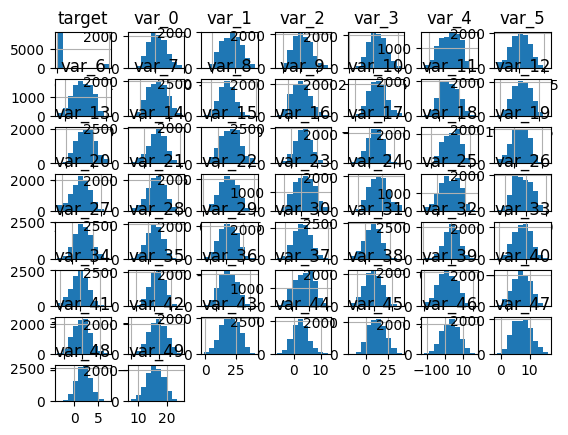

In [20]:
df.hist() ;

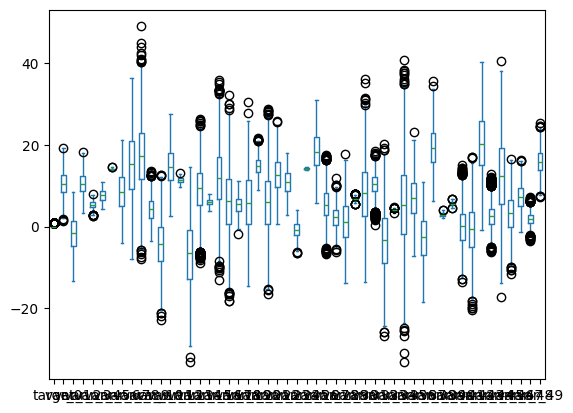

In [21]:
df.plot(kind='box') ;

### Correlation: Independence of Features

In [22]:
# Calculate a correlation matrix
iso_features = df[['target'] + [f'var_{i}' for i in range(50)]]

corr_mat = iso_features.corr()

corr_mat

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
target,1.000000,0.043574,0.066114,0.059939,0.038732,-0.028126,-0.052735,-0.049049,0.052472,-0.060138,...,-0.048415,0.046831,0.046523,-0.052515,0.045255,0.050636,0.055105,0.029874,-0.038527,-0.039557
var_0,0.043574,1.000000,-0.009854,0.011217,-0.008830,-0.011991,-0.004008,-0.005610,0.010324,0.002143,...,-0.017735,0.008473,0.013734,0.021657,0.011481,-0.007350,-0.001388,0.010983,-0.003014,-0.006168
var_1,0.066114,-0.009854,1.000000,0.025620,-0.001012,-0.007787,-0.002027,-0.018065,-0.004419,0.024228,...,-0.012141,0.000944,0.010871,0.001363,-0.010561,-0.014996,0.011586,0.015015,-0.007402,-0.010730
var_2,0.059939,0.011217,0.025620,1.000000,0.004626,0.003042,0.009377,-0.014958,-0.002831,-0.010006,...,-0.015676,-0.001984,0.008702,-0.002698,-0.014033,0.006582,0.000033,0.019182,-0.006128,0.023475
var_3,0.038732,-0.008830,-0.001012,0.004626,1.000000,-0.011308,0.004225,-0.014157,-0.007376,0.001228,...,-0.012295,0.013620,-0.001306,0.002114,-0.006729,0.002133,0.007527,0.018795,-0.005085,0.013717
var_4,-0.028126,-0.011991,-0.007787,0.003042,-0.011308,1.000000,-0.020643,-0.004096,-0.001834,0.003835,...,0.006545,-0.000525,-0.011105,0.002464,0.001220,-0.004567,-0.013192,0.022225,-0.008804,0.014925
var_5,-0.052735,-0.004008,-0.002027,0.009377,0.004225,-0.020643,1.000000,0.015994,0.016200,0.002981,...,0.000999,-0.003686,-0.002560,-0.002469,-0.001667,0.023947,0.009096,-0.016727,0.014813,-0.008814
var_6,-0.049049,-0.005610,-0.018065,-0.014958,-0.014157,-0.004096,0.015994,1.000000,-0.002434,0.006529,...,-0.000391,-0.003957,-0.000081,0.013318,-0.002290,-0.004444,0.010051,-0.005251,0.014332,0.008234
var_7,0.052472,0.010324,-0.004419,-0.002831,-0.007376,-0.001834,0.016200,-0.002434,1.000000,-0.019602,...,-0.000739,0.016092,-0.009378,0.009921,-0.005740,-0.011136,0.016135,0.006741,-0.002834,0.002422
var_8,-0.060138,0.002143,0.024228,-0.010006,0.001228,0.003835,0.002981,0.006529,-0.019602,1.000000,...,0.013479,-0.006359,-0.007322,0.020018,-0.004483,0.003823,0.003681,-0.001141,-0.001220,0.007712


Text(0.5, 23.52222222222222, 'Features')

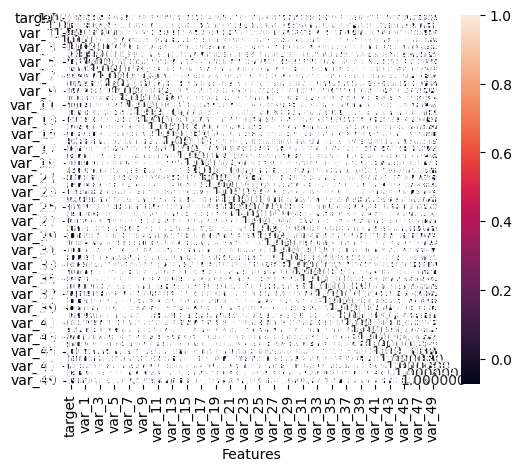

In [23]:
# Heatmap of the correlation matrix
sns.heatmap(
    corr_mat,
    square=True,
    annot=True,
    fmt='2f',
    cbar=True,
)

plt.xlabel('Features')
plt.xlabel('Features')

### Create Two Dataframes (Copies, Not Slices)
1. Successful Transactions
1. Unsuccessful Transactions

In [24]:
# Create a dataframe of successful transactions
successful_df = df[df['target'] == 1].copy()

# Create a dataframe of unsuccessful transactions
unsuccessful_df = df[df['target'] == 0].copy()

## Processing



### Single Cross Validation ( CV )

#### Two data sets with target and features

In [25]:
# Split data frame into target and features
target_col = 'target'
target = df[ target_col]
features = df.drop(columns=[target_col])

In [26]:
target

,target
0,0
1,0
2,0
3,0
4,0
...,...
9995,0
9996,0
9997,0
9998,0


In [27]:
features

,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,2.5791,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,8.5524,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,1.2145,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,6.8202,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,10.1102,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,16.0253,-2.7417,13.0579,4.6907,7.6733,14.4044,4.4485,15.6440,28.7052,4.5230,...,5.4078,-6.0609,5.3959,14.3071,0.7175,0.8099,3.0246,6.3355,1.2195,15.0416
9996,8.2377,5.8972,11.4494,6.0994,5.8279,14.2108,10.4431,16.1281,24.1290,4.1572,...,6.5495,-3.7137,-2.4108,22.0010,6.6314,7.7139,2.1874,11.9021,3.3370,15.4100
9997,7.4000,-0.5939,5.4020,5.4715,8.9772,13.7754,0.5061,31.4915,19.9258,1.0844,...,5.7283,-3.6798,1.2850,11.7876,0.3499,23.6263,2.4554,7.4933,1.0810,19.3749
9998,7.7726,-4.0555,8.6391,6.4168,8.1651,13.8262,8.7265,27.7635,20.2590,8.4112,...,5.5500,3.6771,7.1521,13.3076,2.2369,19.4285,7.5065,6.9602,3.7997,19.1259


#### Define an empty Gaussian Naïve Bayes model using Sklearn

In [28]:
# Create an empty GNB model
modelGNB = GaussianNB()

#### Divide the two data sets you created in step 10 into training and testing subsets, i.e. train-test split.

In [29]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
     features,
     target,
     test_size=0.25
)

In [30]:
# Verify shape of each data set from Train Test Split
for i in [ X_train, X_test, y_train, y_test ]:
  print(i.shape)
  print(type(i))

(7500, 50)
<class 'pandas.core.frame.DataFrame'>
(2500, 50)
<class 'pandas.core.frame.DataFrame'>
(7500,)
<class 'pandas.core.series.Series'>
(2500,)
<class 'pandas.core.series.Series'>


#### Train ( fit ) the model using the training subset of the dataset.

In [31]:
# Train ( fit ) the model
modelGNB.fit( (X_train), y_train)

GaussianNB()

#### Test the model ( predict ) using the testing subset of the dataset.

In [32]:
# Make predicitons using the model
pred_results = modelGNB.predict(X_test)
pred_results * 1000

array([0, 0, 0, ..., 0, 0, 0])

#### Calculate and report the accuracy.

In [33]:
# Display accuracy
acc = metrics.accuracy_score( y_test,pred_results )
acc * 100

91.16

#### Present a confusion matrix and heatmap

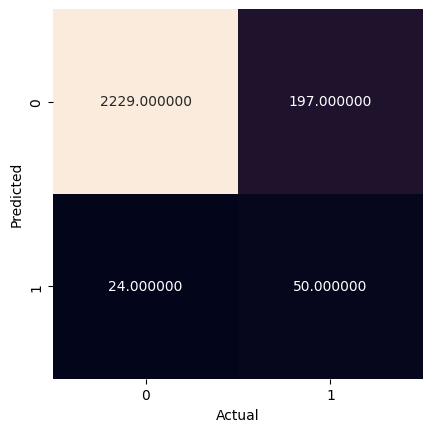

In [34]:
# Display a confusion matrix and heatmap
mat =  metrics.confusion_matrix(
    y_test,
    pred_results
)

sns.heatmap( mat.T,
    square=True,
    annot=True,
    fmt = "2f",
    cbar = False,
)
plt.xlabel('Actual')
plt.ylabel('Predicted');

#### Present the results of a Classification Report (sklearn.metrics.classification_report).

In [35]:
# Display a classification report
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

           0       0.92      0.99      0.95      2253
           1       0.68      0.20      0.31       247

    accuracy                           0.91      2500
   macro avg       0.80      0.60      0.63      2500
weighted avg       0.89      0.91      0.89      2500



## Data Visualization/Communication of Results


### Data Visualization

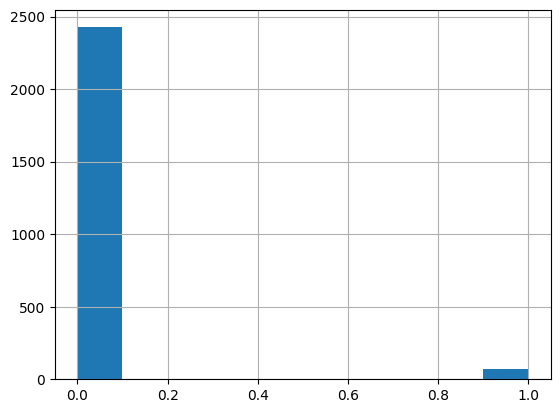

In [36]:
pd.Series(pred_results).hist() ;

### Conclusion

- var_0 thru var_16 gave us 91% accuracy, increase from 90% in Pass-02
- Bad at predicting no-transactions
- OK at predicting a successful transaction
- Low false positive (we predict customer will make a transaction but customer does not)
- Med-high false negative (we predict customer will not make a transaction but customer does)

### Future work


- For Pass-03, use all columns and rows
- Balance the dataset (way more unsuccessful transactions vs. successful transactions)